In [123]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'/projectnb/batmanlab/mragoza/lung-project/notebooks/IPMI-2027'

In [124]:
import sys, os

def add_path(path):
    if path not in sys.path:
        sys.path.append(path)

add_path(os.environ['LP_ROOT'])
import project

add_path(os.environ['PROJECT'] + '/' + 'param_search')
import param_search as ps

ps.set_backend('sge')
ps.set_verbose(False)

# Phantom reconstruction

In [125]:
subject_split = {
    'train': ['10049K', '10056H', '10081G', '10096T', '10114V', '10124Y', '10127E', '10130T', '10153F', '10155J', '10179X', '10181K', '10196X', '10211T', '10212V', '10213X', '10217F', '10227I', '10233D', '10245K', '10261I', '10265Q', '10301U', '10314D', '10328O', '10332F', '10367Y', '10372R', '10395D', '10426O', '10458B', '10469G', '10481W', '10502E', '10503G', '10507O', '10512H', '10523M', '10524O', '10539B', '10552T', '10560S', '10561U', '10564A', '10566E', '10567G', '10572Z', '10624S', '10635X', '10641S', '10646C', '10663C', '10679R', '10699X', '10705S', '10724W', '10736D', '10761C', '10794R', '10815Z', '10829K', '10842C', '10843E', '10883Q', '10887Y', '10888A', '10908G', '10919L', '10947Q', '10961K', '10973R', '10975V', '10990R', '11005V', '11007Z', '11027F', '11049P', '11063J', '11085T', '11114A', '11120V', '11123B', '11139Q', '11153K', '11193W', '11198G', '11211Y', '11221B', '11224H', '11225J', '11226L', '11235M', '11240F', '11247T', '11260L', '11267Z', '11281T', '11329V', '11350M', '11363V', '11404J', '11455A', '11468J', '11477K', '11498S', '11506R', '11514Q', '11516U', '11545B', '11560X', '11600J', '11613S', '11616Y', '11618C', '11676Q', '11690K', '11708D', '11713W', '11716C', '11721V', '11743F', '11746L', '11752G', '11782P', '11783R', '11815E', '11819M', '11828N', '11830A', '11850G', '11852K', '11858W', '11866V', '11879E', '11881R', '11901X', '11903B', '11943N', '11947V', '11972U', '11998M', '12052J', '12069A', '12146S', '12187G', '12231J', '12294H', '12339D', '12362Y', '12418Z', '12457J', '12466K', '12477P', '12478R', '12515X', '12516Z', '12519F', '12560C', '12599D', '12607C', '12608E', '12651F', '12676V', '12683S', '12696B', '12816L', '12825M', '12831H', '12851N', '12878H', '12895H', '12903G', '12905K', '12962W', '12964A', '13034M', '13053Q', '13065X', '13071S', '13084B', '13092A', '13093C', '13103F', '13111E', '13149D', '13170U', '13242T', '13248F', '13267J', '13273E', '13282F', '13297S', '13301J', '13340T', '13341V', '13350W', '13354E', '13358M', '13365J', '13370C', '13383L', '13384N', '13398Y', '13404T', '13407Z', '13419G', '13428H', '13460D', '13488Z', '13489B', '13498C', '13501R', '13507D', '13517G', '13528L', '13542F', '13563N', '13586Z', '13632G', '13651K', '13682V', '13686D', '13702B', '13704F', '13719S', '13728T', '13736S', '13767D', '13780V', '13816Q', '13845X', '13864B', '13866F', '13901H', '13916U', '13925V', '13945B', '13947F', '13998W', '14013J', '14031L', '14047A', '14075F', '14084G', '14113N', '14121M', '14133T', '14157H', '14173F', '14180C', '14194N', '14201K', '14217Z', '14232V', '14241W', '14257L', '14278T', '14293P', '14307A', '14309E', '14329K', '14332Z', '14386W', '14390N', '14417H', '14462M', '14471N', '14508K', '14525K', '14526M', '14632L', '14633N', '14646W', '14668G', '14683C', '14684E', '14685G', '14704K', '14705M', '14729A', '14732P', '14771Z', '14774F', '14814R', '14817X', '14834X', '14845C', '14857J', '14863E', '14875L', '14880E', '14909C', '14964K', '14987W', '14991N', '15040R', '15073G', '15075K', '15078Q', '15082H', '15088T', '15102N', '15140V', '15152C', '15156K', '15163H', '15164J', '15165L', '15204V', '15212U', '15217E', '15221V', '15224B', '15232A', '15237K', '15262J', '15271K', '15297C', '15312Y', '15349V', '15350G', '15357U', '15384X', '15450K', '15473W', '15488J', '15489L', '15502D', '15527T', '15532M', '15537W', '15549D', '15607R', '15623P', '15635W', '15650S', '15661X', '15690E', '15699W', '15745D', '15799A', '15807Z', '15811Q', '15827F', '15840X', '15848N', '15885T', '15894U', '15900P', '15909H', '15911U', '15929N', '15934G', '15965R', '16021S', '16045G', '16059R', '16060C', '16065M', '16069U', '16091N', '16118H', '16266W', '16300W', '16347W', '16353R', '16402E', '16411F', '16440M', '16472Z', '16527Y', '16540Q', '16573F', '16605S', '16637F', '16675N', '16700M', '16716B', '16747M', '16783Q', '16853L', '16954R', '16977D', '17011U', '17022Z', '17041D', '17089F', '17104B', '17137Q', '17144N', '17173U', '17212E', '17233M', '17255W', '17266B', '17337Y', '17366F', '17385J', '17409X', '17414Q', '17428B', '17433U', '17461Z', '17473G', '17505T', '17509B', '17557M', '17573K', '17617E', '17629L', '17696A', '17722B', '17757U', '17790S', '17836Q', '17847V', '17862R', '17894E', '17897K', '17920F', '17922J', '17939A', '17952S', '17955Y', '17995K', '18015H', '18043M', '18103E', '18126Q', '18140K', '18153T', '18184E', '18278N', '18317X', '18374J', '18395R', '18403Q', '18434B', '18451B', '18452D', '18505Y', '18515B', '18525E', '18553J', '18563M', '18629Q', '18633H', '18674V', '18677B', '18682U', '18687E', '18703C', '18761Q', '18786G', '18798N', '18801C', '18830J', '18845W', '18935X', '18960W', '18982G', '19049D', '19059G', '19091C', '19139E', '19143V', '19251Y', '19324Z', '19339M', '19356M', '19367R', '19396Y', '19410S', '19415C', '19478A', '19549X', '19558Y', '19560L', '19594C', '19598K', '19612E', '19637U', '19666B', '19673Y', '19679K', '19760T', '19783F', '19784H', '19785J', '19819A', '19839G', '19849J', '19880D', '19908Z', '19913S', '19922T', '19950Y', '20005W', '20006Y', '20019H', '20024A', '20064M', '20088A', '20102U', '20117H', '20149U', '20188E', '20195B', '20245Q', '20286E', '20306K', '20332L', '20349C', '20378J', '20385G', '20453X', '20519B', '20566K', '20589W', '20592L', '20609C', '20623W', '20632X', '20640W', '20668S', '20678V', '20682M', '20689A', '20703U', '20738N', '20748Q', '20792T', '20803Y', '20807G', '20867Y', '20901Y', '20970R', '20976D', '20977F', '21004Z', '21010U', '21012Y', '21042H', '21052K', '21065T', '21106H', '21150K', '21163T', '21168D', '21175A', '21176C', '21189L', '21223L', '21224N', '21272Y', '21279M', '21293G', '21384J', '21391G', '21398U', '21399W', '21410K', '21419C', '21433W', '21438G', '21461B', '21467N', '21469R', '21484N', '21494Q', '21508B', '21521T', '21526D', '21538K', '21556M', '21559S', '21572K', '21586V', '21587X', '21595W', '21604X', '21611U', '21614A', '21622Z', '21640B', '21647P', '21660H', '21741H', '21769D', '21778E', '21800X', '21813G', '21837U', '21844R', '21850M', '21877G', '21886H', '21897M', '21899Q', '21933Q', '21968J', '22002A', '22055V', '22078H', '22114L', '22116P', '22148C', '22193H', '22210H', '22224S', '22253Z', '22261Y', '22308Y', '22312P', '22325Y', '22357L', '22389Y', '22423Y', '22464M', '22483Q', '22484S', '22487Y', '22495X', '22497B', '22536L', '22592V', '22597F', '22600U', '22604C', '22617L', '22637R', '22663S', '22678F', '22726Q', '22736T', '22745U', '22746W', '22759F', '22827W', '22832P', '22855B', '22877L', '22891F', '22912N', '22920M', '22928C', '22946E', '22961A', '22986Q', '23023N', '23037Y', '23052U', '23074E', '23075G', '23091E', '23094K', '23108V', '23123R', '23124T', '23136A', '23150U', '23155E', '23165H', '23193M', '23239K', '23252C', '23266N', '23269T', '23284P', '23287V', '23293Q', '23310Q', '23326F', '23342D', '23436M', '23500V', '23526N', '23549Z', '23558A', '23574Y', '23577E', '23618S', '23636U', '23656A', '23657C', '23699S', '23705N', '23725T', '23743V', '23746B', '23799W', '23803N', '23816W', '23819C', '23821P', '23851Y', '23902P', '23934C', '24064G', '24080E', '24106W', '24113T', '24123W', '24137H', '24151B', '24154H', '24181K', '24186U', '24205Y', '24213X', '24271L', '24318L', '24331D', '24348U', '24350H', '24383W', '24390T', '24394B', '24438V', '24447W', '24449A', '24480U', '24514L', '24576H', '24581A', '24608U', '24638D', '24646C', '24652X', '24679R', '24682G', '24684K', '24691H', '24699X', '24705S', '24711N', '24714T', '24744C', '24757L', '24761C', '24763G', '24777R', '24810P', '24830V', '24867S', '24873N', '24911V', '24927K', '24950F', '24954N', '24989G', '25003R', '25007Z', '25051C', '25072K', '25096Y', '25120V', '25125F', '25130Y', '25231E', '25245P', '25276A', '25303D', '25309P', '25311C', '25328T', '25335Q', '25347X', '25360P', '25380V', '25381X', '25388L', '25389N', '25400B', '25407P', '25410E', '25454Y', '25552Y', '25601L', '25602N', '25674M', '25703T', '25728J', '25762J', '25767T', '25782P', '25888F', '25894A', '25900V', '25914G', '25923H', '25926N', '25943N', '25950K', '25991Y', '26004Y', '26012X', '26146S'],
    'test': ['10432J', '10490X', '10568I', '10571X', '10634V', '10709A', '10728E', '10880K', '11255S', '11353S', '11542V', '11750C', '12139V', '12147U', '12273Z', '12422Q', '12506W', '12593R', '12630X', '12795D', '12812D', '12861Q', '13264D', '13477U', '13573Q', '13799Q', '14374P', '14788Q', '14905U', '15272M', '15413E', '15617U', '15905Z', '16058P', '16064K', '16142E', '16277B', '16390X', '16463Y', '16514P', '17102X', '17247X', '17476M', '17904H', '18274F', '18341U', '18351X', '18498B', '18593V', '18714H', '18736R', '18808Q', '18886K', '18940Q', '19024N', '19393S', '19627R', '19686H', '19730K', '19912Q', '19921R', '20008C', '20296H', '20400C', '20529E', '20543Y', '20696X', '21170Q', '21534C', '21615C', '21679C', '21838W', '21892C', '22031H', '22113J', '22151R', '22198R', '22430V', '22667A', '22873D', '22914R', '22983K', '23077K', '23312U', '23615M', '23838G', '23930U', '23940X', '24269Y', '24279B', '24431H', '24887Y', '24973R', '25165R', '25320D', '25403H', '25704V', '25835K', '26066U', '26112B'],
    'val': ['10017X', '10020M', '10031R', '10478H', '10806Y', '10817D', '10849Q', '11099E', '11181P', '11195A', '11292Y', '11325N', '11440N', '11512M', '11556G', '11968D', '12223K', '12248A', '12336X', '13255C', '13530Y', '13533E', '13578A', '13648V', '14240U', '14261C', '14330V', '14380K', '14550J', '14745Y', '14754Z', '14837D', '14924Y', '15072E', '15132W', '15267T', '15319M', '15424J', '15606P', '15898C', '16076R', '16128K', '16132B', '16216H', '16294B', '16537B', '16546C', '16613R', '16823C', '17533Y', '17688B', '18364G', '18397V', '18519J', '18840M', '18871X', '19027T', '19056A', '19096M', '19429N', '19579G', '19733Q', '19887R', '20151H', '20375D', '20412J', '20435V', '20622U', '20659R', '20770J', '20818L', '20981W', '21064R', '21083V', '21153Q', '21765V', '21842N', '22092B', '22135T', '22170V', '22182C', '22348K', '22504Y', '22566U', '22720E', '23011G', '23181F', '23741R', '24012N', '24059N', '24116Z', '24377B', '24396F', '24562W', '24643W', '25205D', '25310A', '25694S', '25695U', '26071N'],
}

In [126]:
protocol_keys = ['params.forward_mat', 'params.inverse_mat']
material_types = ['LE', 'NH']

def load_optim_jobs(base_dir):
    index_cols = [*protocol_keys, 'params.subject']
    jobs = ps.load(base_dir)
    jobs = jobs[jobs['params.forward_mat'].isin(material_types)]
    return jobs.set_index(index_cols, verify_integrity=True)

def load_train_jobs(base_dir):
    index_cols = [*protocol_keys, 'params.random_seed']
    jobs = ps.load(base_dir)
    jobs = jobs[jobs['params.forward_mat'].isin(material_types)]
    return jobs.set_index(index_cols, verify_integrity=True)

optim_jobs = load_optim_jobs('../copdgene/2026-10-30_optimize')
train_jobs = load_train_jobs('../copdgene/2026-10-30_train')

In [127]:
optim_metrics = ps.outputs(
    optim_jobs.reset_index(),
    meta_cols=['base_dir', 'job_name', 'job_id'],
    output_name='outputs/optimize/default/eval_metrics.csv',
    read_csv_kws={'index_col': 0},
    skip_errors=True
)

optim_jobs[~optim_jobs.job_name.isin(optim_metrics.job_name)]

 39%|███▉      | 234/600 [00:01<00:02, 156.95it/s]Job job_5d326a7760f61bad: file not found
Job job_059d6c9b50d12971: file not found
100%|██████████| 600/600 [00:03<00:00, 176.34it/s]


job_name  \
params.forward_mat params.inverse_mat params.subject                         
NH                 NH                 11099E          job_902ccc4df71bc40a   
                                      12248A          job_5d326a7760f61bad   
                                      13648V          job_059d6c9b50d12971   
                                      12139V          job_9487b4a1df252f52   
                                      18341U          job_6f703577465bce7b   
                                      22151R          job_e30da360a03f09ea   
                                      24431H          job_dbb1c00462166a25   

                                                      job_state  n_submits  \
params.forward_mat params.inverse_mat params.subject                         
NH                 NH                 11099E          SUBMITTED          2   
                                      12248A          SUBMITTED          2   
                                      13648V          SUBMITTED          2   
                                      12139V          SUBMITTED          2   
                                      18341U          SUBMITTED          2   
                                      22151R          SUBMITTED          2   
                                      24431H          SUBMITTED          2   

                                                       job_id  node_id  \
params.forward_mat params.inverse_mat params.subject                     
NH                 NH                 11099E          8372527  scc-k02   
                                      12248A          8372531     None   
                                      13648V          8372533     None   
                                      12139V          8372553     None   
                                      18341U          8372560     None   
                                      22151R          8372570     None   
                                      24431H          8372573  scc-q30   

                                                       runtime  \
params.forward_mat params.inverse_mat params.subject             
NH                 NH                 11099E          02:13:03   
                                      12248A              None   
                                      13648V              None   
                                      12139V              None   
                                      18341U              None   
                                      22151R              None   
                                      24431H          02:50:11   

                                                                                                 stdout  \
params.forward_mat params.inverse_mat params.subject                                                      
NH                 NH                 11099E            [eval 15] alpha = 0.0001  delta = 0.0000e+00...   
                                      12248A            [eval 15] alpha = 0.0001  delta = 0.0000e+00...   
                                      13648V            [eval 14] alpha = 0.0001  delta = 0.0000e+00...   
                                      12139V            [eval 15] alpha = 0.0001  delta = 0.0000e+00...   
                                      18341U            [eval 22] alpha = 0.0000  delta = 0.0000e+00...   
                                      22151R            [eval 15] alpha = 0.0001  delta = 9.0949e-13...   
                                      24431H            [eval 15] alpha = 0.0001  delta = 0.0000e+00...   

                                                                                                 stderr  \
params.forward_mat params.inverse_mat params.subject                                                      
NH                 NH                 11099E          WARNING: Newton solver failed to converge (ite...   
                                      12248A          WARNING: Newton solver failed to converge (ite...   
      

In [128]:
train_metrics = ps.outputs(
    train_jobs.reset_index(),
    meta_cols=['base_dir', 'job_name', 'job_id'],
    output_name='outputs/training/default/eval_metrics.csv',
    skip_errors=True
)

train_jobs[~train_jobs.job_name.isin(train_metrics.job_name)]

100%|██████████| 9/9 [00:00<00:00, 43.12it/s]


,,,job_name,job_state,n_submits,job_id,node_id,runtime,stdout,stderr,base_dir,work_dir,...,output_type,array_idx,last_live_at,state_source,finalized,finalized_at,output_exists,output_fsize,output_mtime,has_typo
params.forward_mat,params.inverse_mat,params.random_seed,,,,,,,,,,,,,,,,,,,,,


In [129]:
# select best seed x epoch combinations by validation loss

epoch_scores = (
    train_metrics.loc[train_metrics.phase.eq('val')]
    .groupby(protocol_keys + ['params.random_seed', 'epoch'])['loss'].mean() \
    .reset_index()
)

best_epochs = epoch_scores.loc[
    epoch_scores.groupby(protocol_keys)['loss'].idxmin()
]

best_epochs

,params.forward_mat,params.inverse_mat,params.random_seed,epoch,loss
10,LE,LE,0,10,0.000257
65,NH,LE,2,10,0.000830
76,NH,NH,0,10,0.000318


In [130]:
# filter train metrics to best seed x epochs

merge_keys = protocol_keys + ['params.random_seed', 'epoch']

best_train_metrics = train_metrics.merge(
    best_epochs[merge_keys],
    on=merge_keys,
    how='inner',
    validate='many_to_one'
)

best_train_metrics

,epoch,phase,batch,loss,grad_norm,group,label,num_voxels,E_vox.mean,E_vox.std,...,job_id,params.forward_mat,params.inverse_mat,params.random_seed,params.config,params.variant,params.subjects,params.conv_channels,params.learning_rate,params.tv_reg_weight
0,10,test,1,0.000142,0.0,NaN,NaN,4541879.0,1549.202720,559.550729,...,8382011,LE,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
1,10,test,2,0.000139,0.0,NaN,NaN,4788462.0,1880.597742,502.650455,...,8382011,LE,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
2,10,test,3,0.000054,0.0,NaN,NaN,3164649.0,2192.737101,447.272019,...,8382011,LE,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
3,10,test,4,0.000525,0.0,NaN,NaN,4376246.0,1594.991894,540.448406,...,8382011,LE,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
4,10,test,5,0.000206,0.0,NaN,NaN,6728297.0,1801.924859,485.573083,...,8382011,LE,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,10,val,96,0.000465,0.0,NaN,NaN,3448083.0,1937.686925,578.402861,...,8382017,NH,NH,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
596,10,val,97,0.000153,0.0,NaN,NaN,3877114.0,1565.121597,531.774154,...,8382017,NH,NH,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
597,10,val,98,0.000214,0.0,NaN,NaN,4601201.0,1302.735255,458.655469,...,8382017,NH,NH,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001
598,10,val,99,0.000198,0.0,NaN,NaN,3710610.0,1910.586378,412.553935,...,8382017,NH,NH,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-09-15,"16514P,20748Q,11007Z,14771Z,13651K,15900P,1531...",8,0.0001,0.0001


In [131]:
# concat evaluation metrics to compare methods
import pandas as pd

optim_method = 'Baseline'
train_method = 'Ours'

eval_phase = 'test'

compare_metrics = pd.concat([
    optim_metrics[
        optim_metrics['params.subject'].isin(subject_split[eval_phase])
    ].assign(method=optim_method),
    best_train_metrics[
        best_train_metrics['phase'].eq(eval_phase)
    ].assign(method=train_method)
], ignore_index=True)


In [132]:
# infer subject ID from voxel count (confirmed unique)

sid_lookup = optim_metrics[['num_voxels', 'params.subject']] \
    .drop_duplicates() \
    .set_index('num_voxels', verify_integrity=True)['params.subject']

compare_metrics['subject'] = compare_metrics['num_voxels'].map(sid_lookup)

compare_metrics['protocol'] = (
    compare_metrics['params.forward_mat'] + ' → ' +
    compare_metrics['params.inverse_mat']
)

sid_lookup

num_voxels
4088362    10017X
3703108    10020M
4398155    10031R
3262363    10478H
4601201    10806Y
            ...  
2347183    25403H
5568392    25704V
4373385    25835K
2513958    26066U
2943106    26112B
Name: params.subject, Length: 200, dtype: object

In [133]:
# aggregate metrics across subjects
from scipy.stats import iqr

metric_keys = ['u_cell.nrmse', 'E_vox.nrmse', 'E_vox.pcorr']
group_keys = ['protocol', 'method']

compare_metrics.groupby(group_keys)[metric_keys] \
    .agg(['count', 'mean', 'std', 'median', iqr])

u_cell.nrmse                                          \
                         count      mean       std    median       iqr   
protocol method                                                          
LE → LE  Baseline          100  0.003994  0.008357  0.002630  0.001026   
         Ours              100  0.018589  0.014151  0.015517  0.008098   
NH → LE  Baseline          100  0.008460  0.004018  0.007691  0.003513   
         Ours              100  0.035640  0.022250  0.031950  0.013909   
NH → NH  Baseline           96  0.003016  0.001464  0.002610  0.000964   
         Ours              100  0.020598  0.013088  0.017761  0.009481   

                  E_vox.nrmse                                          \
                        count      mean       std    median       iqr   
protocol method                                                         
LE → LE  Baseline         100  0.258397  0.126601  0.234369  0.133663   
         Ours             100  0.179723  0.059252  0.174097  0.065962   
NH → LE  Baseline         100  0.613712  0.666172  0.349796  0.310635   
         Ours             100  0.476737  0.154995  0.443318  0.168425   
NH → NH  Baseline          96  0.252800  0.120513  0.233483  0.121323   
         Ours             100  0.214526  0.096660  0.198091  0.070966   

                  E_vox.pcorr                                          
                        count      mean       std    median       iqr  
protocol method                                                        
LE → LE  Baseline         100  0.822612  0.188029  0.866154  0.055961  
         Ours             100  0.852403  0.055891  0.862792  0.055707  
NH → LE  Baseline         100  0.624432  0.219249  0.688973  0.221608  
         Ours             100  0.789573  0.079353  0.807720  0.091813  
NH → NH  Baseline          96  0.840784  0.150267  0.869467  0.058531  
         Ours             100  0.817347  0.068609  0.833531  0.077317

In [134]:
# configure labels and order for plotting

readable_names = {
    'E_vox.nrmse': '$E$ normalized RMSE',
    'E_vox.pcorr': '$E$ Pearson correlation',
    'E_vox.scorr': '$E$ rank correlation',
    'E_cell.nrmse': '$E$ normalized RMSE',
    'E_cell.pcorr': '$E$ Pearson correlation',
    'E_cell.scorr': '$E$ rank correlation',
    'u_cell.nrmse': '$u$ normalized RMSE',
}
protocol_order = ['LE → LE', 'NH → NH', 'NH → LE']

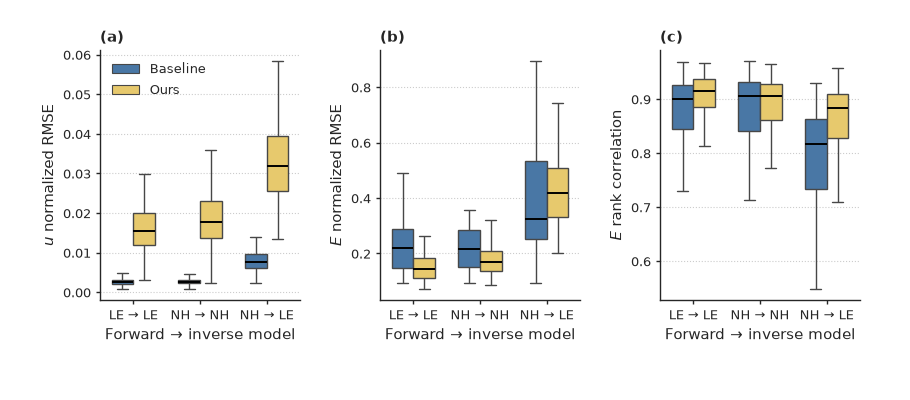

In [135]:
import matplotlib.pyplot as plt
import project.visual.matplotlib as mpl_viz
import seaborn as sns

sns.set_theme(style='ticks', context='paper', font_scale=1.1)
palette = {'Baseline': '#4477AA', 'Ours': '#EECC66'}

fig, axes = mpl_viz.subplot_grid(
    n_rows=1,
    n_cols=3,
    ax_height=2.5,
    ax_width=2,
    spacing=0.8,
    padding=(1.0, 0.5, 1.0, 0.5)
)

metric_keys = ['u_cell.nrmse', 'E_cell.nrmse', 'E_cell.scorr']

for col, metric in enumerate(metric_keys):
    ax = axes[0, col]

    sns.boxplot(
        data=compare_metrics,
        x='protocol',
        y=metric,
        hue='method',
        order=protocol_order,
        hue_order=[optim_method, train_method],
        palette=palette,
        saturation=0.9,
        width=0.65,
        showfliers=False,
        medianprops={'color': 'black', 'linewidth': 1.4},
        ax=ax
    )
    
    ax.set_xlabel('Forward → inverse model')
    ax.set_ylabel(readable_names[metric])
    ax.set_title(f'({chr(97 + col)})', loc='left', fontweight='bold')
    ax.grid(axis='y', linestyle=':')
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=3)
    sns.despine(ax=ax)

    ax.get_legend().remove()

handles, labels = axes[0,0].get_legend_handles_labels()
axes[0,0].legend(handles, labels, frameon=False, ncols=1, loc='upper left')

#axes[0,0].set_ylim(0.0, 0.125)
#axes[0,1].set_ylim(0.0, 1.25)
#axes[0,2].set_ylim(-0.125, 1.0)

plt.pause(1.0)

In [136]:
#fig.savefig('phantom_results_plot.png', bbox_inches='tight', dpi=400)
#fig.savefig('phantom_results_plot.pdf', bbox_inches='tight', dpi=400)

In [137]:
# Subjects and rows contributing to each box
display(
    compare_metrics.groupby(['protocol', 'method']).agg(
        subjects=('subject', 'nunique'),
        rows=('subject', 'size'),
    )
)

subjects  rows
protocol method                  
LE → LE  Baseline       100   100
         Ours           100   100
NH → LE  Baseline       100   100
         Ours           100   100
NH → NH  Baseline        96    96
         Ours           100   100

In [138]:
def plot_reconstruction(sid):
    pass
    

In [139]:
#fig.savefig('2026-11-05_phantom_grid.png', bbox_inches='tight', dpi=400)
#fig.savefig('2026-11-05_phantom_grid.pdf', bbox_inches='tight', dpi=400)

# COPDGene clinical evaluation

# BMC-4DCT clinical evaluation

In [144]:
case_split = {
    'train': ['4DCT_10_1', '4DCT_1_1', '4DCT_2_1', '4DCT_2_2', '4DCT_4_1', '4DCT_6_1', '4DCT_7_3', '4DCT_8_1', '4DCT_8_2', 'unknown_12_1', 'unknown_13_1', 'unknown_14_1', 'unknown_16_1', 'unknown_20_1', 'unknown_23_1', 'unknown_26_1', 'unknown_32_1', 'unknown_34_1', 'unknown_36_1', 'unknown_37_1', 'unknown_38_1', 'unknown_42_1', 'unknown_42_4', 'unknown_44_1', 'unknown_45_1', 'unknown_49_1', 'unknown_50_1', 'unknown_52_1', 'unknown_53_1'],
    'test': ['unknown_17_1', 'unknown_17_3', 'unknown_28_1', 'unknown_29_1', 'unknown_30_1', 'unknown_31_1', 'unknown_33_1', 'unknown_43_1', 'unknown_47_1'],
    'val': ['unknown_15_1', 'unknown_18_1', 'unknown_19_1', 'unknown_22_1', 'unknown_27_1', 'unknown_39_1', 'unknown_40_1', 'unknown_40_5', 'unknown_51_1'],
}

In [145]:
protocol_keys = ['params.curr_phase', 'params.material_type']

def load_optim_jobs(base_dir):
    index_cols = [*protocol_keys, 'params.subject']
    return ps.load(base_dir).set_index(index_cols, verify_integrity=True)

def load_train_jobs(base_dir):
    index_cols = [*protocol_keys, 'params.random_seed']
    return ps.load(base_dir).set_index(index_cols, verify_integrity=True)

optim_jobs = load_optim_jobs('../bmc-4dct/2026-11-15_optimize')
train_jobs = load_train_jobs('../bmc-4dct/2026-11-15_train')

In [146]:
optim_metrics = ps.outputs(
    optim_jobs.reset_index(),
    meta_cols=['base_dir', 'job_name', 'job_id'],
    output_name='outputs/optimize/default/eval_metrics.csv',
    read_csv_kws={'index_col': 0},
    skip_errors=True
)

optim_jobs[~optim_jobs.job_name.isin(optim_metrics.job_name)]

100%|██████████| 324/324 [00:01<00:00, 170.38it/s]


,,,job_name,job_state,n_submits,job_id,node_id,runtime,stdout,stderr,base_dir,work_dir,...,params.E_beta,params.num_trials,array_idx,last_live_at,state_source,finalized,finalized_at,output_exists,output_fsize,output_mtime
params.curr_phase,params.material_type,params.subject,,,,,,,,,,,,,,,,,,,,,
0,NH,unknown_27_1,job_f40049769b890cc3,FAILED,1,8641338,scc-k09,06:00:01,[eval 15] alpha = 0.0001 delta = 6.5484e-11...,WARNING: Newton solver failed to converge (ite...,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,None,3,NaN,None,history,True,2026-11-16T10:56:47,False,None,None
90,NH,unknown_27_1,job_5d5dc23416012f0d,FAILED,1,8641354,scc-f03,06:00:01,[eval 15] alpha = 0.0001 delta = 7.2760e-12...,WARNING: Newton solver failed to converge (ite...,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,None,3,NaN,None,history,True,2026-11-16T10:56:47,False,None,None
0,NH,unknown_31_1,job_4eec57aae35c9470,RUNNING,1,8641521,scc-x06,02:58:53,[eval 15] alpha = 0.0001 delta = 7.8944e-10...,WARNING: Newton solver failed to converge (ite...,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,None,3,NaN,2026-11-16T14:41:24,status,None,None,False,None,None
80,NH,unknown_47_1,job_5126f400bc723777,RUNNING,1,8641590,scc-q34,00:50:44,[eval 15] alpha = 0.0001 delta = 8.9494e-10...,WARNING: Newton solver failed to converge (ite...,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,None,3,NaN,2026-11-16T14:41:24,status,None,None,False,None,None


In [147]:
train_metrics = ps.outputs(
    train_jobs.reset_index(),
    meta_cols=['base_dir', 'job_name', 'job_id'],
    output_name='outputs/training/default/eval_metrics.csv',
    skip_errors=True
)

train_jobs[~train_jobs.job_name.isin(train_metrics.job_name)]

100%|██████████| 54/54 [00:00<00:00, 135.07it/s]


,,,job_name,job_state,n_submits,job_id,node_id,runtime,stdout,stderr,base_dir,work_dir,...,params.E_max,params.E_beta,array_idx,last_live_at,state_source,finalized,finalized_at,output_exists,output_fsize,output_mtime
params.curr_phase,params.material_type,params.random_seed,,,,,,,,,,,,,,,,,,,,,


In [148]:
# select best training (seed, epoch) by validation loss

epoch_scores = (
    train_metrics.loc[train_metrics.phase.eq('val')]
    .groupby(protocol_keys + ['params.random_seed', 'epoch'])['loss'].mean() \
    .reset_index()
)

best_epochs = epoch_scores.loc[
    epoch_scores.groupby(protocol_keys)['loss'].idxmin()
]

best_lookup = best_epochs.set_index(
    ['params.curr_phase', 'params.material_type'], verify_integrity=True
)
best_lookup

params.random_seed  epoch      loss
params.curr_phase params.material_type                                     
0                 LE                                     0     23  0.041524
                  NH                                     0     16  0.040917
10                LE                                     0     23  0.059343
                  NH                                     0     25  0.059857
20                LE                                     0     23  0.098553
                  NH                                     0     23  0.099973
30                LE                                     0     21  0.136889
                  NH                                     0     25  0.137764
40                LE                                     0     14  0.217935
                  NH                                     0     16  0.219170
60                LE                                     2     12  0.209306
                  NH                                     0     19  0.206970
70                LE                                     2     17  0.139587
                  NH                                     0     20  0.141967
80                LE                                     2     23  0.078943
                  NH                                     2     23  0.078859
90                LE                                     0     19  0.040631
                  NH                                     2     19  0.040005

In [149]:
# filter train metrics to best (seed, epoch) per protocol

merge_keys = protocol_keys + ['params.random_seed', 'epoch']

best_train_metrics = train_metrics.merge(
    best_epochs[merge_keys],
    on=merge_keys,
    how='inner',
    validate='many_to_one'
)

best_train_metrics

,epoch,phase,batch,loss,grad_norm,group,label,num_voxels,E_vox.mean,E_vox.std,...,params.curr_phase,params.material_type,params.random_seed,params.config,params.variant,params.subjects,params.reg_tag,params.mat_tag,params.E_max,params.E_beta
0,23,test,1,0.096010,0.000000,NaN,NaN,2037548.0,12612.231377,29034.405843,...,0,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
1,23,test,2,0.187036,0.000000,NaN,NaN,2227797.0,10374.658539,26355.176564,...,0,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
2,23,test,3,0.057852,0.000000,NaN,NaN,2460214.0,14028.231938,29895.963050,...,0,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
3,23,test,4,0.068262,0.000000,NaN,NaN,3342098.0,19959.548996,35204.554504,...,0,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
4,23,test,5,0.036755,0.000000,NaN,NaN,2314763.0,15315.853338,31725.936217,...,0,LE,0,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
783,19,train,25,0.027357,0.591693,NaN,NaN,NaN,NaN,NaN,...,90,NH,2,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
784,19,train,26,0.015013,0.310100,NaN,NaN,NaN,NaN,NaN,...,90,NH,2,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
785,19,train,27,0.077835,0.809195,NaN,NaN,NaN,NaN,NaN,...,90,NH,2,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None
786,19,train,28,0.019120,1.548049,NaN,NaN,NaN,NaN,NaN,...,90,NH,2,/projectnb/batmanlab/mragoza/lung-project/note...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",gil,const,100000.0,None


In [150]:
# concat evaluation metrics to compare estimation methods
import pandas as pd

optim_method = 'Baseline'
train_method = 'Ours'

eval_phase = 'test'

compare_metrics = pd.concat([
    optim_metrics[
        optim_metrics['params.subject'].isin(case_split[eval_phase])
    ].assign(method=optim_method),
    best_train_metrics[
        best_train_metrics['phase'].eq(eval_phase)
    ].assign(method=train_method)
], ignore_index=True)

compare_metrics

,group,label,num_voxels,E_vox.mean,E_vox.std,E_vox.rms,num_cells,E_cell.mean,E_cell.std,E_cell.rms,...,params.E_beta,params.num_trials,method,epoch,phase,batch,loss,grad_norm,params.random_seed,params.subjects
0,NaN,NaN,2037548.0,1828.980810,7150.423702,7380.632082,163807.0,1899.274469,6201.946940,6486.246168,...,None,3.0,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,2037548.0,1520.838336,6239.073247,6421.758655,163807.0,1576.625361,5376.670207,5603.064344,...,None,3.0,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,2037548.0,5642.569835,14709.239935,15754.375069,163807.0,5832.971991,13478.452280,14686.464453,...,None,3.0,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,2037548.0,4047.692748,11772.416391,12448.839474,163807.0,4186.474751,10523.511869,11325.673177,...,None,3.0,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,2037548.0,14791.709757,26522.565758,30368.423929,163807.0,15342.587782,25144.385366,29455.646577,...,None,3.0,Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,NaN,NaN,2314763.0,10885.681988,27590.736443,29660.526122,196907.0,10517.275494,18441.396800,21229.653783,...,None,NaN,Ours,19.0,test,5.0,0.037887,0.0,2.0,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4..."
318,NaN,NaN,3055252.0,8935.799282,24297.009897,25888.089902,254952.0,9180.472204,16966.740768,19291.225004,...,None,NaN,Ours,19.0,test,6.0,0.072023,0.0,2.0,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4..."
319,NaN,NaN,2454804.0,8380.531048,23697.137912,25135.386328,205446.0,7859.297951,15406.363665,17295.219156,...,None,NaN,Ours,19.0,test,7.0,0.039707,0.0,2.0,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4..."
320,NaN,NaN,1972018.0,12181.417900,29225.618593,31662.655040,166036.0,11578.601175,18955.715369,22212.229746,...,None,NaN,Ours,19.0,test,8.0,0.063497,0.0,2.0,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4..."


In [151]:
# recover missing case IDs from unique voxel counts

case_lookup = (
    optim_metrics[['num_voxels', 'params.subject']]
    .drop_duplicates()
    .set_index('num_voxels', verify_integrity=True)['params.subject']
)

compare_metrics['subject'] = compare_metrics['num_voxels'].map(case_lookup)
compare_metrics['phase'] = compare_metrics['params.curr_phase']

has_subject = compare_metrics['subject'].notna()
if not has_subject.all():
    print(f'WARNING: {(~has_subject).sum()} rows have unresolved case IDs', file=sys.stderr)

paired_metrics = compare_metrics.loc[has_subject].set_index(
    ['subject', *protocol_keys, 'method'],
    verify_integrity=True,
)
paired_metrics

group  label  \
subject      params.curr_phase params.material_type method                   
unknown_17_1 0                 LE                   Baseline    NaN    NaN   
                               NH                   Baseline    NaN    NaN   
             10                LE                   Baseline    NaN    NaN   
                               NH                   Baseline    NaN    NaN   
             20                LE                   Baseline    NaN    NaN   
...                                                             ...    ...   
unknown_30_1 90                NH                   Ours        NaN    NaN   
unknown_31_1 90                NH                   Ours        NaN    NaN   
unknown_33_1 90                NH                   Ours        NaN    NaN   
unknown_43_1 90                NH                   Ours        NaN    NaN   
unknown_47_1 90                NH                   Ours        NaN    NaN   

                                                              num_voxels  \
subject      params.curr_phase params.material_type method                 
unknown_17_1 0                 LE                   Baseline   2037548.0   
                               NH                   Baseline   2037548.0   
             10                LE                   Baseline   2037548.0   
                               NH                   Baseline   2037548.0   
             20                LE                   Baseline   2037548.0   
...                                                                  ...   
unknown_30_1 90                NH                   Ours       2314763.0   
unknown_31_1 90                NH                   Ours       3055252.0   
unknown_33_1 90                NH                   Ours       2454804.0   
unknown_43_1 90                NH                   Ours       1972018.0   
unknown_47_1 90                NH                   Ours       6288948.0   

                                                                E_vox.mean  \
subject      params.curr_phase params.material_type method                   
unknown_17_1 0                 LE                   Baseline   1828.980810   
                               NH                   Baseline   1520.838336   
             10                LE                   Baseline   5642.569835   
                               NH                   Baseline   4047.692748   
             20                LE                   Baseline  14791.709757   
...                                                                    ...   
unknown_30_1 90                NH                   Ours      10885.681988   
unknown_31_1 90                NH                   Ours       8935.799282   
unknown_33_1 90                NH                   Ours       8380.531048   
unknown_43_1 90                NH                   Ours      12181.417900   
unknown_47_1 90                NH                   Ours       6402.328860   

                                                                 E_vox.std  \
subject      params.curr_phase params.material_type method                   
unknown_17_1 0                 LE                   Baseline   7150.423702   
                               NH                   Baseline   6239.073247   
             10                LE                   Baseline  14709.239935   
                               NH                   Baseline  11772.416391   
             20                LE                   Baseline  26522.565758   
...                                                                    ...   
unknown_30_1 90                NH                   Ours      27590.736443   
unknown_31_1 90                NH                   Ours      24297.009897   
unknown_33_1 90                NH                   Ours      23697.137912   
unknown_43_1 90                NH                   Ours      29225.618593   
unknown_47_1 90                NH                   Ours      19498.155469   

                            

In [152]:
from pathlib import Path

def resolve_config(case_list, curr_phase, material_type):
    config = project.fileio.load_config('../bmc-4dct/2026-11-01_config.yaml')
    
    config['dataset']['variant'] = '2026-11-01'
    config['dataset']['subjects'] = case_list
    config['dataset']['state_pairs'] = [(50, curr_phase)]
    config['dataset']['pipeline_tags']['image_registration'] = 'gil'
    config['dataset']['pipeline_tags']['material_properties'] = 'const'
    config['dataset']['pipeline_tags']['field_interpolation'] = 'int'
    
    config['training']['split']['method'] = None
    config['training']['loaders']['shuffle'] = False
    config['training']['loaders']['batch_size'] = 1
    
    config['training']['pde_solver']['material_type'] = material_type
    config['optimization']['pde_solver']['material_type'] = material_type

    return config

case_ids = case_split['test']
config = resolve_config(case_ids, curr_phase=0, material_type='NH')
examples = project.get_examples(config['dataset'])

Loading ../bmc-4dct/2026-11-01_config.yaml
Gathering examples...
9 total


In [153]:
%%time
from collections import defaultdict
import numpy as np

def load_baseline(case_id, *protocol_vals):
    output_dir = Path(optim_jobs.loc[*protocol_vals, case_id].work_dir) / 'outputs'
    path = output_dir / 'optimize' / 'default' / case_id / 'rasters' / 'E_pred.nii.gz'
    return project.fileio.load_nibabel(path).get_fdata(dtype=np.float32)

def load_trainer(case_ids, *protocol_vals):
    import project.training
    best = best_lookup.loc[*protocol_vals].rename({'params.random_seed': 'seed'})
    output_dir = Path(train_jobs.loc[*protocol_vals, best.seed].work_dir) / 'outputs'
    config = resolve_config(case_ids, *protocol_vals)
    examples = project.get_examples(config['dataset'])
    trainer = project.training.get_trainer(
        examples, config['training'], output_dir=output_dir, device='cuda'
    )
    trainer.load_checkpoint(epoch=int(best.epoch))
    return trainer

def run_inference(trainer, batch):
    outputs = trainer.run_batch(batch, eval_mode=True)
    return outputs['preds']['E'][0,0].detach().cpu().numpy()

E_optim, E_train = {}, {}

protocol_vals = (0, 'LE')
trainer = load_trainer(case_ids, *protocol_vals)

for batch in trainer.train_loader:
    case_id = batch['example'][0].subject
    try:
        E_optim[case_id] = load_baseline(case_id, *protocol_vals)
        E_train[case_id] = run_inference(trainer, batch) 
    except FileNotFoundError as e:
        print('WARNING: {e}', file=sys.stderr)
        continue


Loading ../bmc-4dct/2026-11-01_config.yaml
Gathering examples...
9 total
Splitting data examples
Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
backbone.encoder.unit0.conv.weight                 216	(8, 1, 3, 3, 3)
backbone.encoder.unit0.norm.weight                 8	(8,)
backbone.encoder.unit0.norm.bias                   8	(8,)
backbone.encoder.unit1.conv.weight                 1728	(8, 8, 3, 3, 3)
backbone.encoder.unit1.norm.weight                 8	(8,)
backbone.encoder.unit1.norm.bias                   8	(8,)
backbone.sublevel.encoder.unit0.conv.weight        3456	(16, 8, 3, 3, 3)
backbone.sublevel.encoder.unit0.norm.weight        16	(16,)
backbone.sublevel.encoder.unit0.norm.bias          16	(16,)
backbone.sublevel.encoder.unit1.conv.weight        6912	(16, 16, 3, 3, 3)
backbone.sublevel.encoder.unit1.norm.weight        16	(16,)
backbone.sublevel.encoder.unit1.norm.bias          16	(16,)
backbone.sublevel.sublevel.encod

In [154]:
%%time
from tqdm.notebook import tqdm

def load_regions(ex):
    project.utils.set_verbose(False)

    masks = {}
    for path in ex.paths['init_state']['segment_dir'].iterdir():
        if not str(path).endswith('nii.gz'):
            continue
        name = path.name.split('.')[0]
        if name.startswith('gt'): # skip high-attenuation masks
            continue
        masks[name] = project.fileio.load_nibabel(path).get_fdata() > 0

    masks['airways'] = masks.pop('lung_airways')
    masks['vessels'] = masks.pop('lung_arteries') | masks.pop('lung_veins')

    masks['parenchyma'] = (
        masks.pop('lung_upper_lobe_left') |
        masks.pop('lung_lower_lobe_left') | 
        masks.pop('lung_upper_lobe_right') | 
        masks.pop('lung_middle_lobe_right') | 
        masks.pop('lung_lower_lobe_right')
    ) & ~(masks['vessels'] | masks['airways'])

    for key in ['emphysema', 'ggo', 'consolidation', 'nodule', 'honeycombing', 'pleural_effusion']:
        masks[key] = masks['parenchyma'] & masks[key]
    
    masks['abnormal'] = (
        masks['emphysema'] |
        masks['ggo'] | 
        masks['consolidation'] |
        masks['nodule'] |
        masks['honeycombing'] |
        masks['pleural_effusion']
    )
    masks['normal'] = masks['parenchyma'] & ~masks['abnormal']

    masks['harder'] = masks['parenchyma'] & (
        masks['ggo'] | masks['consolidation'] | masks['nodule']
    )
    masks['softer'] = masks['parenchyma'] & (
        masks['emphysema']
    )

    masks['ambiguous'] = masks['harder'] & masks['softer']
    masks['harder'] = masks['harder'] & ~masks['ambiguous']
    masks['softer'] = masks['softer'] & ~masks['ambiguous']

    project.utils.set_verbose(True)
    return masks

regions = {}
for ex in tqdm(examples):
    regions[ex.subject] = load_regions(ex)

  0%|          | 0/9 [00:00<?, ?it/s]

CPU times: user 28.9 s, sys: 16 s, total: 44.9 s
Wall time: 45.1 s


In [155]:
%%time

def evaluate_regions(E_pred, masks, **metadata):
    rows = []
    for region, mask in masks.items():
        values = E_pred[mask > 0]
        finite = values[np.isfinite(values)]
        rows.append({
            **metadata,
            'region': region,
            'n_voxels': values.size,
            'n_finite': finite.size,
            'mean': finite.mean() if finite.size else np.nan,
            'std': finite.std() if finite.size else np.nan,
            'median': np.median(finite) if finite.size else np.nan,
            'Q1': np.quantile(finite, 0.25) if finite.size else np.nan,
            'Q3': np.quantile(finite, 0.75) if finite.size else np.nan,
            'min': finite.min() if finite.size else np.nan,
            'max': finite.max() if finite.size else np.nan
        })
    return rows

rows = []
for ex in tqdm(examples):
    case_id = ex.subject
    if case_id not in E_optim:
        print(f'Skipping {case_id}: baseline not available', file=sys.stderr)
        continue
    rows.extend(evaluate_regions(E_train[case_id], regions[case_id], method=train_method, case_id=case_id))
    rows.extend(evaluate_regions(E_optim[case_id], regions[case_id], method=optim_method, case_id=case_id))

region_eval = pd.DataFrame(rows)
region_eval

  0%|          | 0/9 [00:00<?, ?it/s]

CPU times: user 2min 38s, sys: 11.1 s, total: 2min 49s
Wall time: 2min 49s


,method,case_id,region,n_voxels,n_finite,mean,std,median,Q1,Q3,min,max
0,Ours,unknown_17_1,pleural_effusion,334093,334093,24212.601562,38211.601562,2277.907471,403.229614,28162.164062,1.000000,100000.000000
1,Ours,unknown_17_1,honeycombing,7,7,37.044788,20.363014,30.411257,22.903769,43.568184,16.339333,79.618996
2,Ours,unknown_17_1,nodule,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ours,unknown_17_1,lt-850,65109923,65109923,3075.087891,417.776093,3078.887207,3078.887207,3078.887207,1.000000,100000.000000
4,Ours,unknown_17_1,lung_airways_wall,48927,48927,14403.378906,30887.220703,1086.929199,179.273285,5468.648438,1.000000,100000.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
319,Baseline,unknown_47_1,abnormal,743247,743247,34675.460938,39933.285156,11415.004883,568.199707,74218.835938,0.000000,100000.015625
320,Baseline,unknown_47_1,normal,5231694,5231694,25742.207031,34624.796875,5290.960938,492.878143,44398.503906,0.000000,100000.015625
321,Baseline,unknown_47_1,harder,123251,123251,30217.873047,38096.734375,6117.634277,563.616272,59741.710938,0.000000,100000.015625
322,Baseline,unknown_47_1,softer,614568,614568,35704.617188,40266.941406,13089.060547,593.581177,77605.203125,1.000000,100000.015625


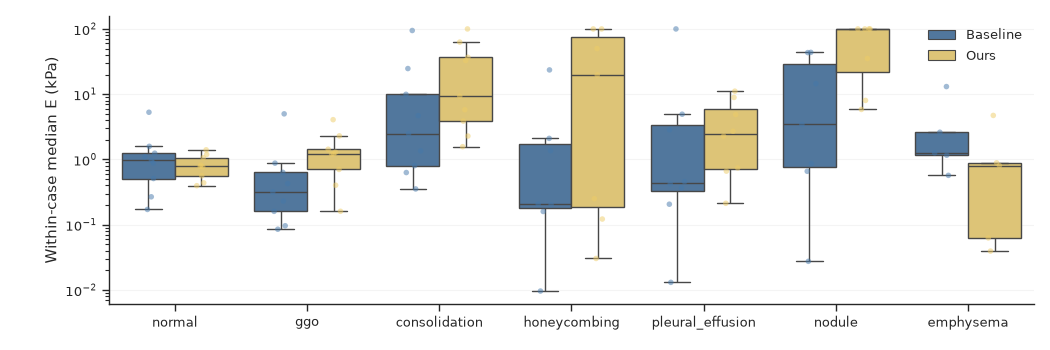

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_regions(df, regions=None, metric='median', log=False):
    sns.set_theme(style='ticks', context='paper', font_scale=1.1)

    if regions is not None:
        df = df.loc[df['region'].isin(regions)]
    else:
        regions = df['region'].drop_duplicates().tolist()

    df = df.copy()
    df['E_kPa'] = df[metric] / 1000
    df = df.loc[np.isfinite(df['E_kPa'])]
    if log:
        df = df.loc[df['E_kPa'] > 0]
    if df.empty:
        raise ValueError('No valid results for this selection.')

    methods = ['Baseline', 'Ours']
    palette = {'Baseline': '#4477AA', 'Ours': '#EECC66'}
    #palette = dict(zip(regions, sns.color_palette('husl', n_colors=len(regions))))

    fig, ax = plt.subplots(figsize=(max(8, len(regions) * 1.5), 3.5))
    common = dict(
        data=df,
        x='region',
        y='E_kPa', 
        hue='method',
        order=regions,
        hue_order=methods,
        palette=palette,
        ax=ax
    )
    sns.boxplot(**common, showfliers=False)
    sns.stripplot(
        **common,
        dodge=True,
        jitter=0.12,
        size=4,
        alpha=0.5,
        legend=False
    )

    if log:
        ax.set_yscale('log')

    ax.set(xlabel='', ylabel=f'Within-case {metric} E (kPa)')
    #ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.2)
    ax.legend(title='', frameon=False)
    ax.spines[['top', 'right']].set_visible(False)

    fig.tight_layout()

    return fig, ax

fig, axes = plot_regions(
    region_eval,
    regions=[
        'normal',
        'ggo',
        'consolidation',
        'honeycombing',
        'pleural_effusion',
        'nodule',
        'emphysema'
    ],
    log=True
)
plt.pause(1.0)

In [161]:
fig.savefig('bmc_regions_plot.png', bbox_inches='tight')
fig.savefig('bmc_regions_plot.pdf', bbox_inches='tight')

In [162]:
%%time

def probability_greater(a, b):
    import scipy.stats

    a, b = a.ravel(), b.ravel()    
    if not a.size or not b.size:
        return np.nan
    
    # Mann-Whitney U statistic (also Wilcoxon rank-sum)
    ranks = scipy.stats.rankdata(np.concatenate([a, b]))
    u = ranks[:a.size].sum() - a.size * (a.size + 1) / 2

    # P(a > b) + 0.5 * P(a == b)
    return u / (a.size * b.size)
    

def evaluate_ranking(E_pred, masks, **metadata):
    from project.evaluation import metrics

    E_normal = E_pred[masks['normal']]
    E_harder = E_pred[masks['harder']]
    E_softer = E_pred[masks['softer']]

    return {
        **metadata,
        'n_normal': np.isfinite(E_normal).sum(),
        'n_harder': np.isfinite(E_harder).sum(),
        'n_softer': np.isfinite(E_softer).sum(),
        'AUC_hard': probability_greater(E_harder, E_normal),
        'AUC_soft': probability_greater(E_normal, E_softer),
    }

rows = []
for ex in tqdm(examples):
    case_id = ex.subject
    rows.append(evaluate_ranking(
        E_train[case_id], regions[case_id], method=train_method, case_id=case_id
    ))
    rows.append(evaluate_ranking(
        E_optim[case_id], regions[case_id], method=optim_method, case_id=case_id
    ))

rank_eval = pd.DataFrame(rows)
rank_eval

  0%|          | 0/9 [00:00<?, ?it/s]

CPU times: user 22.7 s, sys: 206 ms, total: 22.9 s
Wall time: 22.9 s


,method,case_id,n_normal,n_harder,n_softer,AUC_hard,AUC_soft
0,Ours,unknown_17_1,1538873,42009,29,0.781619,0.695628
1,Baseline,unknown_17_1,1538873,42009,29,0.667113,0.167461
2,Ours,unknown_17_3,1215185,81009,0,0.464289,NaN
3,Baseline,unknown_17_3,1215185,81009,0,0.436101,NaN
4,Ours,unknown_28_1,2264535,46049,657,0.724666,0.493004
5,Baseline,unknown_28_1,2264535,46049,657,0.564012,0.392861
6,Ours,unknown_29_1,3053011,80378,37,0.530649,0.414566
7,Baseline,unknown_29_1,3053011,80378,37,0.428853,0.478232
8,Ours,unknown_30_1,2143193,25125,0,0.597394,NaN
9,Baseline,unknown_30_1,2143193,25125,0,0.500991,NaN


In [163]:
rank_eval.groupby('method')[['AUC_hard', 'AUC_soft']].describe()

AUC_hard                                                              \
            count      mean       std       min       25%       50%       75%   
method                                                                          
Baseline      9.0  0.518874  0.083239  0.428853  0.455472  0.500991  0.564012   
Ours          9.0  0.626595  0.108581  0.464289  0.533425  0.618751  0.724666   

                   AUC_soft                                                    \
               max    count      mean       std       min       25%       50%   
method                                                                          
Baseline  0.667113      5.0  0.402225  0.139941  0.167461  0.392861  0.446148   
Ours      0.781619      5.0  0.580826  0.151609  0.414566  0.493004  0.520645   

                              
               75%       max  
method                        
Baseline  0.478232  0.526424  
Ours      0.695628  0.780288

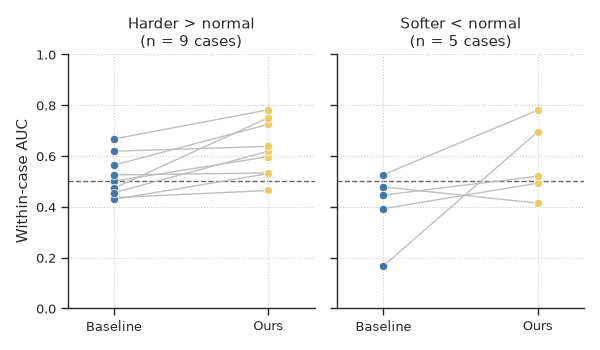

In [164]:
import numpy as np
import matplotlib.pyplot as plt

def plot_paired_auc(df, methods=('Baseline', 'Ours')):
    metrics = {
        'AUC_hard': 'Harder > normal',
        'AUC_soft': 'Softer < normal',
    }
    colors = ['#4477AA', '#EECC66']
    fig, axes = plt.subplots(1, 2, figsize=(6, 3.5), sharey=True)

    for ax, (metric, title) in zip(axes, metrics.items()):
        paired = (
            df.pivot(index='case_id', columns='method', values=metric)
            .reindex(columns=list(methods))
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        for values in paired.to_numpy():
            ax.plot([0, 1], values, color='0.75', lw=1, zorder=1)

        for x, (method, color) in enumerate(zip(methods, colors)):
            ax.scatter(
                np.full(len(paired), x), paired[method],
                color=color, edgecolor='white', linewidth=0.5,
                s=35, zorder=2,
            )

        ax.axhline(0.5, color='0.4', ls='--', lw=1, zorder=0)
        ax.set(
            xticks=[0, 1],
            xticklabels=methods,
            xlim=(-0.3, 1.3),
            ylim=(0, 1),
            title=f'{title}\n(n = {len(paired)} cases)',
        )
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(linestyle=':')

    axes[0].set_ylabel('Within-case AUC')
    fig.tight_layout()
    return fig, axes

fig, axes = plot_paired_auc(rank_eval)
plt.pause(1.0)

In [165]:
fig.savefig('bmc_paired_auc_plot.png', bbox_inches='tight')
fig.savefig('bmc_paired_auc_plot.pdf', bbox_inches='tight')

In [166]:
region_voxels = region_eval.groupby(['region', 'case_id']).n_voxels.mean()

region_fractions = (
    region_voxels
    .div(region_voxels.loc['parenchyma'], level='case_id')
    .rename('fraction')
    .reset_index()
)

largest = region_fractions.loc[
    region_fractions.groupby('region')['fraction'].idxmax()
].set_index('region')
largest

,case_id,fraction
region,,
abnormal,unknown_17_3,0.430480
airways,unknown_17_1,0.019900
ambiguous,unknown_47_1,0.000003
consolidation,unknown_17_1,0.020071
emphysema,unknown_47_1,0.102860
ggo,unknown_17_3,0.030551
harder,unknown_17_3,0.037966
honeycombing,unknown_47_1,0.000990
lt-850,unknown_43_1,46.580680


In [167]:
# load images
images = {}
for ex in examples:
    images[ex.subject] = project.fileio.load_nibabel(ex.paths['input_image']).get_fdata()

Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_17_1/images/unknown_17_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_17_3/images/unknown_17_3_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_28_1/images/unknown_28_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_29_1/images/unknown_29_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_30_1/images/unknown_30_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_31_1/images/unknown_31_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown_33_1/images/unknown_33_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/unknown

[('unknown_17_3', 'ggo', np.int64(145)), ('unknown_17_1', 'consolidation', np.int64(107)), ('unknown_29_1', 'nodule', np.int64(192)), ('unknown_47_1', 'emphysema', np.int64(144))]


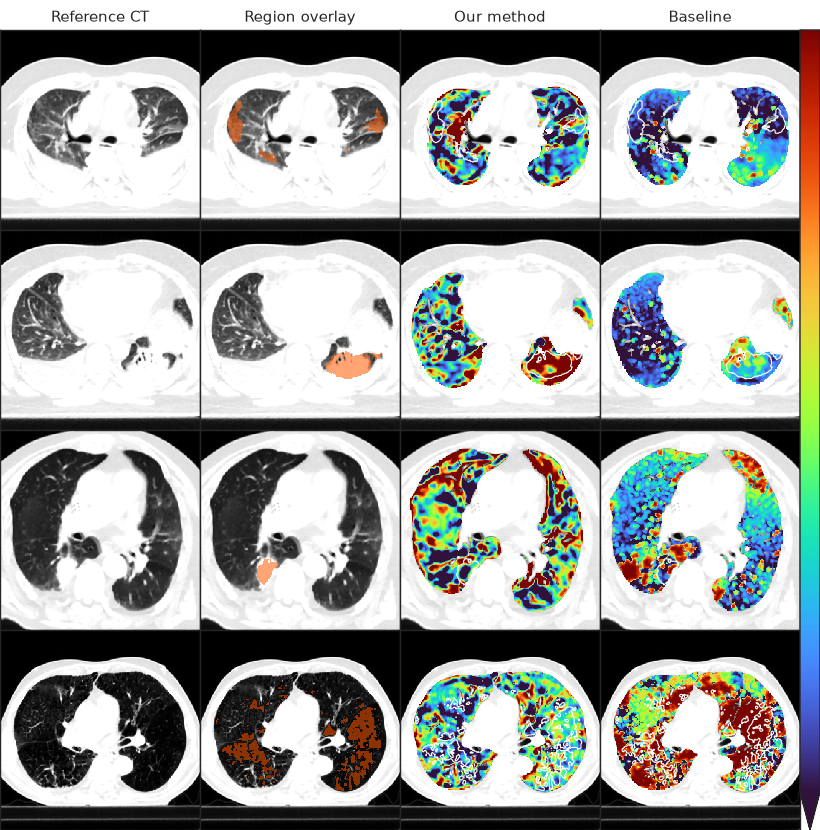

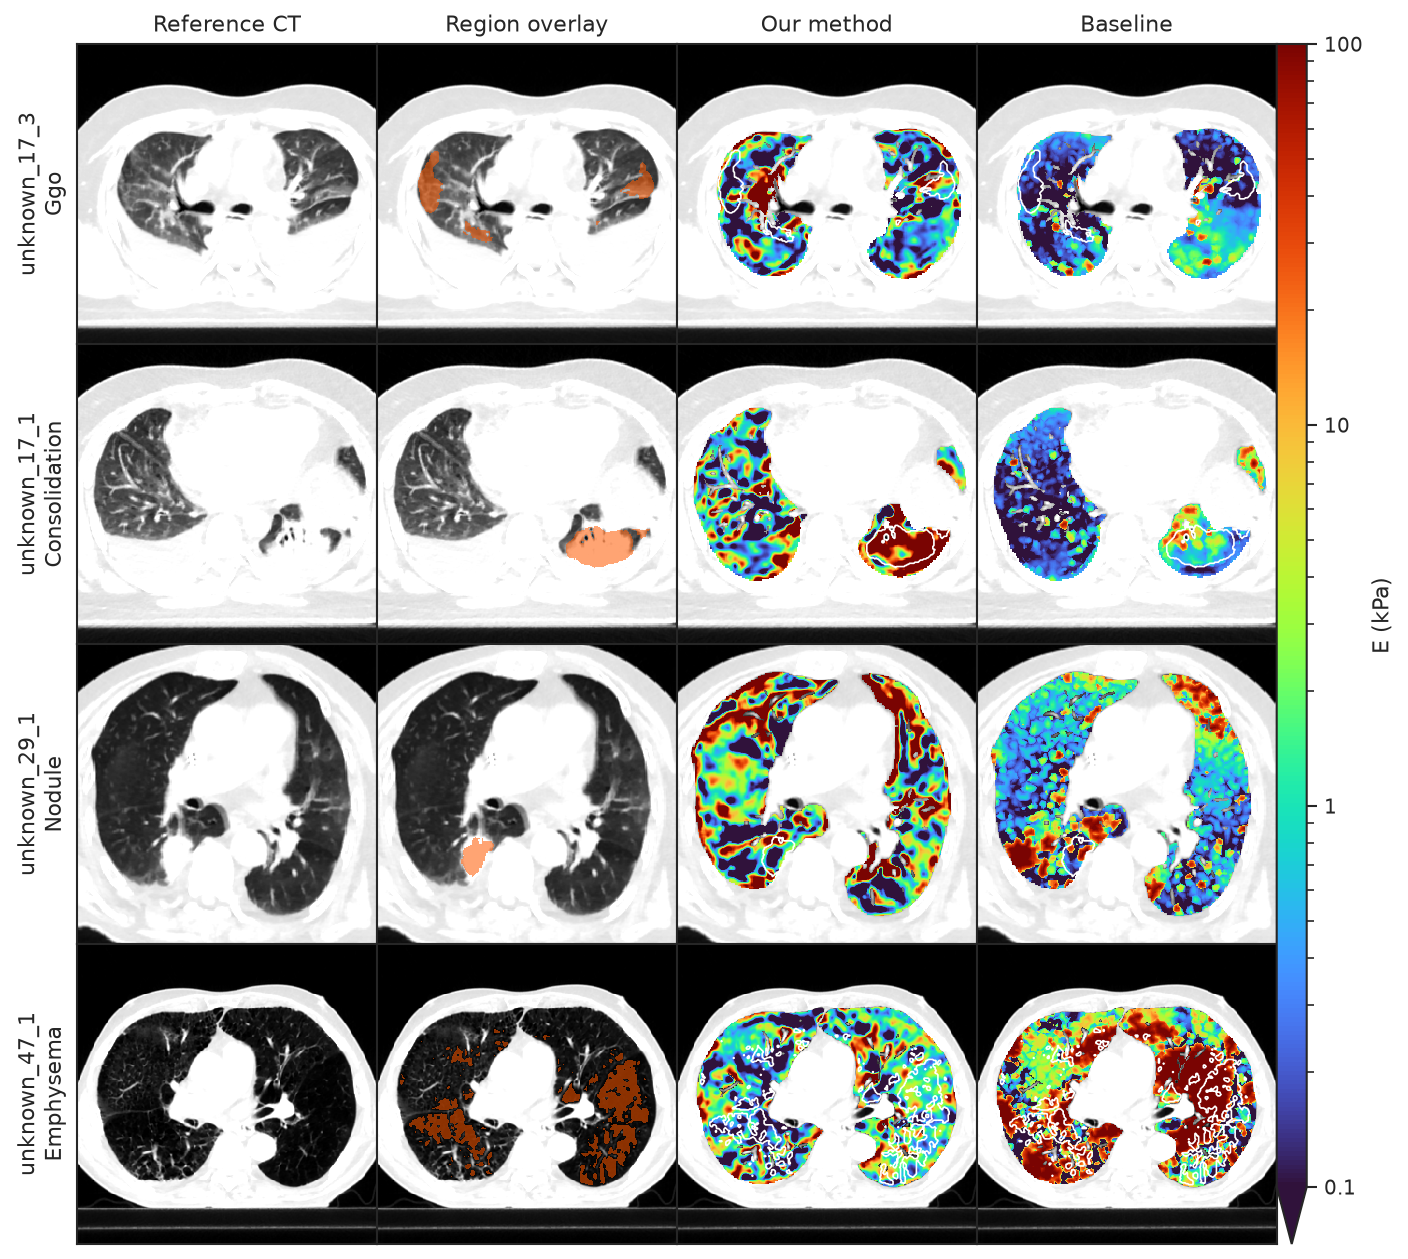

In [169]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import project.visual.matplotlib as mpl_viz

def compute_bbox(mask, margin=10):
    """Square crop in axes 0/1; ordinary bounding box along axis 2."""
    voxels = np.stack(np.nonzero(mask), axis=0)
    if voxels.shape[1] == 0:
        raise ValueError("Cannot crop an empty mask.")

    shape = np.asarray(mask.shape)
    lo = voxels.min(axis=1)
    hi = voxels.max(axis=1) + 1

    side = int((hi[:2] - lo[:2]).max() + 2 * margin)
    if side > shape[:2].min():
        raise ValueError("Square crop exceeds in-plane dimensions.")

    start = np.maximum(lo - margin, 0)
    stop = np.minimum(hi + margin, shape)
    start[:2] = np.clip(
        (lo[:2] + hi[:2] - side) // 2,
        0, shape[:2] - side,
    )
    stop[:2] = start[:2] + side
    return start, stop

def select_slice(lesion_mask, lung_mask, crop, criterion='area'):
    lung = lung_mask[crop] > 0
    lesion = (lesion_mask[crop] > 0) & lung
    n_lesion = lesion.sum(axis=(0, 1))
    n_lung = lung.sum(axis=(0, 1))

    if not n_lesion.any():
        raise ValueError("No lesion voxels in this crop.")

    if criterion == 'prevalence':
        scores = np.divide(
            n_lesion, n_lung,
            out=np.zeros(n_lung.shape, dtype=float),
            where=n_lung > 0,
        )
    elif criterion == 'area':
        scores = n_lesion
    else:
        raise ValueError("criterion must be 'prevalence' or 'area'.")

    return int(scores.argmax()) + crop[2].start

def _slice(vol, bbox, idx):
    lo, hi = bbox
    return vol[lo[0]:hi[0],lo[1]:hi[1],idx].T

def plot_clinical_grid(selections, criterion='prevalence'):
    fig, axes, cax = mpl_viz.subplot_grid(
        n_rows=len(selections),
        n_cols=4,
        ax_height=2,
        ax_width=2,
        spacing=0,
        padding=(0.0, 0.0, 0.0, 0.3),
        cbar_width=0.2
    )
    axes = np.asarray(axes).reshape(len(selections), 4)

    for ax, title in zip(axes[0], ['Reference CT', 'Region overlay', 'Our method', 'Baseline']):
        ax.set_title(title)

    norm = LogNorm(vmin=0.1, vmax=100)  # kPa
    selected_slices = []

    for row, (case_id, lesion_name) in enumerate(selections):
        mask = regions[case_id]['parenchyma']
        lesion = regions[case_id][lesion_name]
        img = images[case_id]
        ours = E_train[case_id]
        baseline = E_optim[case_id]

        if not all(v.shape == mask.shape for v in [img, lesion, ours, baseline]):
            raise ValueError(f"{case_id}: array shapes do not match.")

        bbox = compute_bbox(mask)
        crop = tuple(slice(a, b) for a, b in zip(*bbox))
        idx = select_slice(lesion, mask, crop, criterion)
        selected_slices.append((case_id, lesion_name, idx))

        ct_slice = _slice(img, bbox, idx)
        mask_slice = _slice(mask, bbox, idx)
        lesion_slice = _slice(lesion, bbox, idx)

        for ax in axes[row]:
            ax.imshow(
                ct_slice, origin='lower', cmap='gray',
                vmin=-1000, vmax=0, interpolation='nearest',
            )

        # Transparent background; orange lesion overlay.
        overlay = np.zeros((*lesion_slice.shape, 4))
        overlay[lesion_slice] = [1.0, 0.35, 0.0, 0.55]
        axes[row, 1].imshow(
            overlay, origin='lower', interpolation='nearest'
        )

        for col, volume in [(2, ours), (3, baseline)]:
            values = _slice(volume, bbox, idx) / 1000
            values = np.ma.masked_where(
                ~mask_slice | ~np.isfinite(values) | (values <= 0),
                values,
            )
            im = axes[row, col].imshow(
                values, origin='lower', cmap='turbo',
                norm=norm, interpolation='nearest',
            )
            axes[row, col].contour(
                lesion_slice.astype(float),
                levels=[0.5],
                colors='white',
                linewidths=0.8,
                origin='lower'
            )

        label = lesion_name.replace('_', ' ').capitalize()
        axes[row, 0].set_ylabel(f'{case_id}\n{label}')

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])

    cbar = fig.colorbar(im, cax=cax, extend='min')
    cbar.set_label('E (kPa)')
    cbar.set_ticks([0.1, 1, 10, 100])
    cbar.set_ticklabels(['0.1', '1', '10', '100'])

    return fig, axes, selected_slices

selections = [
    ('unknown_39_1', 'ggo'),
    ('unknown_51_1', 'consolidation'),
    ('unknown_18_1', 'nodule'),
    ('unknown_27_1', 'emphysema'),
]

selections = [
    ('unknown_17_3', 'ggo'),
    ('unknown_17_1', 'consolidation'),
    ('unknown_29_1', 'nodule'),
    ('unknown_47_1', 'emphysema'),
]

fig, axes, selected_slices = plot_clinical_grid(selections)
print(selected_slices)  # Original-volume slice indices
plt.pause(1.0)
fig

In [ ]:
fig.savefig('bmc_clinical_grid.png', bbox_inches='tight')
fig.savefig('bmc_clinical_grid.pdf', bbox_inches='tight')

In [ ]:

axes[0,0].set_title('Input image')
im = axes[0,0].imshow(_slice(image), origin='lower', cmap='gray', clim=(-3, 3))
plt.colorbar(im, cax=axes[0,1])

axes[0,3].set_title('Our method')
axes[0,4].set_title('Baseline inversion')
im = axes[0,3].imshow(_slice(E_pred / 1e3 * mask), origin='lower', cmap='turbo', clim=(0, 100))
im = axes[0,4].imshow(_slice(E_base / 1e3 * mask), origin='lower', cmap='turbo', clim=(0, 100))
plt.colorbar(im, cax=axes[0,5], label='Young\'s modulus (kPa)')

img_cols = [0,3,4]
sep_cols = [2]

for col in img_cols:
    axes[0,col].set_xticks([])
    axes[0,col].set_yticks([])

for col in sep_cols:
    axes[0,col].set_axis_off()

fig

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, max(3, result.region.nunique() * 0.45)))

region_order = result['region'].unique()
methods = result['method'].unique()
offsets = np.linspace(-0.15, 0.15, len(methods))

for method, offset in zip(methods, offsets):
    df = (
        result.loc[result.method.eq(method)]
        .set_index('region')
        .reindex(region_order)
    )
    median = df['median'].to_numpy() / 1000
    q1 = df['Q1'].to_numpy() / 1000
    q3 = df['Q3'].to_numpy() / 1000

    ax.errorbar(
        median, np.arange(len(region_order)) + offset,
        xerr=np.vstack([median - q1, q3 - median]),
        fmt='o', capsize=3, label=method,
    )

ax.set_yticks(np.arange(len(region_order)), region_order)
ax.invert_yaxis()
ax.set_xlabel("Young’s modulus (kPa): median and interquartile range")
ax.set_title(f'{case_id} · {mat_type} · phase {curr_phase}')
ax.grid(axis='x', alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()